<a href="https://colab.research.google.com/github/SriPranathiC/Customer-Segmentation-Project/blob/main/Clustering_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# online retailer to better understand their customers

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


In [ ]:
df = pd.read_excel('online_retail.xlsx', sheet_name=0)

In [ ]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [ ]:
df.describe() # gives only for numeric data

,Quantity,InvoiceDate,Price,Customer ID
count,525461.000000,525461,525461.000000,417534.000000
mean,10.337667,2010-06-28 11:37:36.845017856,4.688834,15360.645478
min,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000
25%,1.000000,2010-03-21 12:20:00,1.250000,13983.000000
50%,3.000000,2010-07-06 09:51:00,2.100000,15311.000000
75%,10.000000,2010-10-15 12:45:00,4.210000,16799.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000
std,107.424110,NaN,146.126914,1680.811316


In [ ]:
# observations - qty min is < 0 , price min < 0 , cutomer ID cnt < than qty - so
# many missing values in customerID

In [ ]:
#for object data
df.describe(include='O')

,Invoice,StockCode,Description,Country
count,525461,525461,522533,525461
unique,28816,4632,4681,40
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,675,3516,3549,485852


In [ ]:
df.isnull().sum()

,0
Invoice,0
StockCode,0
Description,2928
Quantity,0
InvoiceDate,0
Price,0
Customer ID,107927
Country,0


In [ ]:
df[df['Customer ID'].isna()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
525231,538159,21324,NaN,-18,2010-12-09 17:17:00,0.00,NaN,United Kingdom
525232,538158,20892,NaN,-32,2010-12-09 17:17:00,0.00,NaN,United Kingdom
525233,538160,20956,NaN,288,2010-12-09 17:18:00,0.00,NaN,United Kingdom
525234,538161,46000S,Dotcom sales,-100,2010-12-09 17:25:00,0.00,NaN,United Kingdom


In [ ]:
df[df["Quantity"] < 0].head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [ ]:
#if invoive starts with c - cancellation

In [ ]:
# If Customer ID is NaN, you don't know which customer made that transaction.

# You therefore cannot reliably calculate:

# Frequency → how many purchases that customer made
# Monetary → how much that customer spent
# Recency → when that customer last purchased

# And you definitely shouldn't replace the missing ID with something like 0, because that would create a fake customer.

In [ ]:
df[df["Quantity"] < 0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [ ]:
# we want invoice to be a str column not numeric
# we want to do str operations on it
df["Invoice"] = df["Invoice"].astype("str")

In [ ]:
df[df["Invoice"].str.match("^\\d{6}$") == False]
# regex - invoice is not exact 6 letters

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
...,...,...,...,...,...,...,...,...
524695,C538123,22956,36 FOIL HEART CAKE CASES,-2,2010-12-09 15:41:00,2.10,12605.0,Germany
524696,C538124,M,Manual,-4,2010-12-09 15:43:00,0.50,15329.0,United Kingdom
524697,C538124,22699,ROSES REGENCY TEACUP AND SAUCER,-1,2010-12-09 15:43:00,2.95,15329.0,United Kingdom
524698,C538124,22423,REGENCY CAKESTAND 3 TIER,-1,2010-12-09 15:43:00,12.75,15329.0,United Kingdom


In [ ]:
# check if c is the only no. is data
#Find every digit from 0 through 9 and replace it with nothing.
#"Treat the pattern I'm giving you as a regular expression (regex),
#rather than as ordinary text."
df["Invoice"].str.replace("[0-9]", "", regex=True).unique()

array(['', 'C', 'A'], dtype=object)

In [ ]:
df[df["Invoice"].str.startswith("A"  , na=False)]
# take all the NAN as False
# we have just 3 transactions with A

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom


In [ ]:
# Description = "Adjust bad debt"
# These are not customer purchases. They are accounting adjustments.

# Custome ID is also not present need to remove them

Three transactions with the description "Adjust bad debt" were excluded from the customer segmentation dataset. These records represent accounting adjustments rather than customer purchase transactions. They contain extremely large negative prices and missing Customer IDs, which would introduce artificial negative monetary values and cannot be reliably attributed to individual customers. Including these observations in RFM analysis would therefore distort customers' monetary scores and potentially affect the resulting clusters. The records were excluded from the segmentation dataset but retained in the original data for traceability.

In [ ]:
df["Invoice"].str.len().value_counts()

,count
Invoice,
6,515252
7,10209


In [ ]:
df[
    (df["Invoice"].str.len() >= 7) &
    (df["Invoice"].str.startswith("A", na=False))
].shape[0]

3

In [ ]:
df[
    (df["Invoice"].str.len() >= 7) &
    (df["Invoice"].str.startswith("C", na=False))
].shape[0]

10206

In [ ]:
# so out of all invoices 10209 - 3 are A rest all 10206 are C

Cancellations are legitimate business events, but they answer a different question. For my primary segmentation, I wanted to measure purchasing behavior rather than cancellation behavior. A cancellation can introduce a negative quantity and therefore distort the customer's monetary value. If the business wanted to segment customers based on return or cancellation behavior, I would retain them and engineer separate features such as return rate or cancellation frequency.

In [ ]:
# Looking for Stocks - 5 letter words

In [ ]:
df["StockCode"] = df["StockCode"].astype("str")

In [ ]:
df[(df["StockCode"].str.match("^\\d{5}$") == False)]

# 79323P -- we have different last letters

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
12,489436,48173C,DOOR MAT BLACK FLOCK,10,2009-12-01 09:06:00,5.95,13078.0,United Kingdom
23,489436,35004B,SET OF 3 BLACK FLYING DUCKS,12,2009-12-01 09:06:00,4.65,13078.0,United Kingdom
28,489436,84596F,SMALL MARSHMALLOWS PINK BOWL,8,2009-12-01 09:06:00,1.25,13078.0,United Kingdom
...,...,...,...,...,...,...,...,...
525387,538170,84029E,RED WOOLLY HOTTIE WHITE HEART.,2,2010-12-09 19:32:00,3.75,13969.0,United Kingdom
525388,538170,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,2,2010-12-09 19:32:00,3.75,13969.0,United Kingdom
525389,538170,85232B,SET OF 3 BABUSHKA STACKING TINS,2,2010-12-09 19:32:00,4.95,13969.0,United Kingdom
525435,538171,47591D,PINK FAIRY CAKE CHILDRENS APRON,1,2010-12-09 20:01:00,1.95,17530.0,United Kingdom


In [ ]:
# 79323P if this is the only pattern or are there any other patterns



*   StockCode is used to identify products, so we want codes that represent actual products.
* After checking the data, the common product-code pattern is:
5 digits → 85123
5 digits + letter(s) → 85123A, 79323P
* These formats are treated as valid product codes because they represent actual products.
* Other formats such as POST, M, D, etc. can represent postage, discounts, adjustments, or other non-product transactions.
* We exclude non-product StockCodes from the main segmentation dataset.



In [ ]:
#Give me StockCodes that do NOT match format 1 AND do NOT match format 2.
df[(df["StockCode"].str.match("^\\d{5}$") == False) & (df["StockCode"].str.match("^\\d{5}[a-zA-Z]+$") == False)]["StockCode"].unique()

array(['POST', 'D', 'DCGS0058', 'DCGS0068', 'DOT', 'M', 'DCGS0004',
       'DCGS0076', 'C2', 'BANK CHARGES', 'DCGS0003', 'TEST001',
       'gift_0001_80', 'DCGS0072', 'gift_0001_20', 'DCGS0044', 'TEST002',
       'gift_0001_10', 'gift_0001_50', 'DCGS0066N', 'gift_0001_30',
       'PADS', 'ADJUST', 'gift_0001_40', 'gift_0001_60', 'gift_0001_70',
       'gift_0001_90', 'DCGSSGIRL', 'DCGS0006', 'DCGS0016', 'DCGS0027',
       'DCGS0036', 'DCGS0039', 'DCGS0060', 'DCGS0056', 'DCGS0059', 'GIFT',
       'DCGSLBOY', 'm', 'DCGS0053', 'DCGS0062', 'DCGS0037', 'DCGSSBOY',
       'DCGSLGIRL', 'S', 'DCGS0069', 'DCGS0070', 'DCGS0075', 'B',
       'DCGS0041', 'ADJUST2', '47503J ', 'C3', 'SP1002', 'AMAZONFEE'],
      dtype=object)

In [ ]:
## Analyse each stock code if its valid or not
df[df["StockCode"].str.contains("DOT")]['StockCode'].value_counts()


,count
StockCode,
DOT,736


In [ ]:
df[df["StockCode"].str.contains("DOT")].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
2379,489597,DOT,DOTCOM POSTAGE,1,2009-12-01 14:28:00,647.19,NaN,United Kingdom
2539,489600,DOT,DOTCOM POSTAGE,1,2009-12-01 14:43:00,55.96,NaN,United Kingdom
2551,489601,DOT,DOTCOM POSTAGE,1,2009-12-01 14:44:00,68.39,NaN,United Kingdom
2571,489602,DOT,DOTCOM POSTAGE,1,2009-12-01 14:45:00,59.35,NaN,United Kingdom
2619,489603,DOT,DOTCOM POSTAGE,1,2009-12-01 14:46:00,42.39,NaN,United Kingdom


In [ ]:
# no customer Id and postage fees for DOT

In [ ]:
#I followed a profile-first, clean-second approach.
#Before removing records, I investigated the distribution and business meaning of unusual transactions.
#This allowed me to distinguish between genuine business events and records that were unsuitable for my specific modeling objective.
#I then quantified their impact and created explicit exclusion rules.
#This ensured that my RFM features represented actual customer purchasing behavior and that my cleaning decisions were reproducible and business-justified,
#while preserving the original data for traceability."

In [ ]:
# Question 1: Can I identify the customer?
# If Customer ID is missing:

# We don't know who made the purchase.
# We cannot create that customer's RFM profile.
# So exclude it from customer segmentation.

In [ ]:
# Question 2: Is this actually a normal purchase?

# Even after Customer ID is known, you can still have:

# C... → cancellations
# A... → bad-debt/accounting adjustments
# negative quantity → returns/cancellations
# Price = 0 → needs investigation
# unusual StockCodes → postage/discounts/adjustments

# So removing missing Customer IDs doesn't solve these problems.

| **StockCode / Pattern** | **Observed Meaning**                                                                   | **Data Assessment**                                                      | **Action for Clustering** |
| ----------------------- | -------------------------------------------------------------------------------------- | ------------------------------------------------------------------------ | ------------------------- |
| `[0-9]{5}`              | Standard product code                                                                  | Standard product identifier                                              | ✅ **Include**             |
| `[0-9]{5}[A-Za-z]+`     | Product codes with alphabetic suffixes                                                 | Legitimate product codes observed in the dataset                         | ✅ **Include**             |
| `DCGS`                  | Appears valid, but some transactions have negative quantities and missing Customer IDs | Non-standard transaction; not reliably attributable to a customer        | ❌ **Exclude**             |
| `D`                     | Discount transactions                                                                  | Not an actual product purchase                                           | ❌ **Exclude**             |
| `DOT`                   | Postage charges                                                                        | Service/charge rather than a product                                     | ❌ **Exclude**             |
| `M / m`                 | Manual transactions                                                                    | Operational/manual entries rather than standard purchases                | ❌ **Exclude**             |
| `C2`                    | Carriage transaction; business meaning unclear                                         | Insufficient evidence to classify as a normal product                    | ❌ **Exclude**             |
| `C3`                    | Rare transaction; only one occurrence                                                  | Too little evidence and not a standard product code                      | ❌ **Exclude**             |
| `BANK CHARGES / B`      | Bank charges                                                                           | Financial/administrative transaction, not a product purchase             | ❌ **Exclude**             |
| `S`                     | Samples sent to customers                                                              | Not a normal revenue-generating purchase                                 | ❌ **Exclude**             |
| `TESTXXX`               | Testing records                                                                        | Artificial/testing data, not genuine customer activity                   | ❌ **Exclude**             |
| `gift_XXX`              | Gift-card related transactions                                                         | Potentially useful for separate analysis, but lacks customer information | ❌ **Exclude**             |
| `PADS`                  | Padding/packaging-related item                                                         | Appears to represent a legitimate product/item                           | ✅ **Include**             |
| `SP1002`                | Special-request item                                                                   | Very rare; some records have zero pricing, making treatment uncertain    | ❌ **Exclude for now**     |
| `AMAZONFEE`             | Amazon-related fee/shipping charge                                                     | Fee rather than a standard customer product purchase                     | ❌ **Exclude for now**     |
| `ADJUSTX`               | Manual account adjustments                                                             | Accounting/administrative transaction rather than a customer purchase    | ❌ **Exclude for now**     |


Data Cleaning

In [ ]:
cleaned_df = df.copy()

In [ ]:
cleaned_df["Invoice"] = cleaned_df["Invoice"].astype("str")

In [ ]:
mask = (
    cleaned_df["Invoice"].str.match("^\\d{6}$") == True
)
cleaned_df = cleaned_df[mask]

In [ ]:
cleaned_df["StockCode"] = cleaned_df["StockCode"].astype("str")

mask = (
    (cleaned_df["StockCode"].str.match("^\\d{5}$") == True)
    | (cleaned_df["StockCode"].str.match("^\\d{5}[a-zA-Z]+$") == True)
    | (cleaned_df["StockCode"].str.match("^PADS$") == True)
)

cleaned_df = cleaned_df[mask]

cleaned_df


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom


In [ ]:
cleaned_df.dropna(subset=["Customer ID"], inplace=True)

In [ ]:
cleaned_df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,406337.000000,406337,406337.000000,406337.000000
mean,13.619099,2010-07-01 10:11:06.543288320,2.991462,15373.632992
min,1.000000,2009-12-01 07:45:00,0.000000,12346.000000
25%,2.000000,2010-03-26 14:01:00,1.250000,14004.000000
50%,5.000000,2010-07-09 15:48:00,1.950000,15326.000000
75%,12.000000,2010-10-14 17:09:00,3.750000,16814.000000
max,19152.000000,2010-12-09 20:01:00,295.000000,18287.000000
std,97.000659,NaN,4.285876,1677.365907


In [ ]:
len(cleaned_df[cleaned_df["Price"] == 0])

28

In [ ]:

cleaned_df = cleaned_df[cleaned_df["Price"] > 0.0]

In [ ]:
cleaned_df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,406309.000000,406309,406309.000000,406309.000000
mean,13.617924,2010-07-01 10:14:25.869572352,2.991668,15373.722268
min,1.000000,2009-12-01 07:45:00,0.001000,12346.000000
25%,2.000000,2010-03-26 14:01:00,1.250000,14006.000000
50%,5.000000,2010-07-09 15:48:00,1.950000,15326.000000
75%,12.000000,2010-10-14 17:09:00,3.750000,16814.000000
max,19152.000000,2010-12-09 20:01:00,295.000000,18287.000000
std,96.998833,NaN,4.285951,1677.329470


In [ ]:
## keep track of how much data you lost
round((len(df) - len(cleaned_df))*100 / len(df),2)

22.68

In [ ]:
#GOAL

"Group customers based on how they actually purchase."

#Recency — "How recently did they buy?"
#Frequency — "How often did they buy?"
#Monetary — "How much did they spend?"

# They provide a compact customer profile.
# Instead of giving the clustering algorithm dozens of potentially redundant variables, I give it three interpretable dimensions.


# RFM is a well-known framework specifically designed to summarize transactional customer behavior.

'Group customers based on how they actually purchase.'

In [ ]:
# Other metrics could certainly be added, but I wanted to start with a compact, interpretable feature set and avoid redundant or noisy variables.
# If the business objective required deeper behavioral segmentation, I could extend the feature set with metrics such as
# average order value, product diversity, or return rate and validate whether they actually improve the clustering."

In [ ]:
#Product price per unit in sterling

In [ ]:
cleaned_df["SalesLineTotal"] = cleaned_df["Quantity"] * cleaned_df["Price"]

/tmp/ipykernel_1213/4090189634.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_df["SalesLineTotal"] = cleaned_df["Quantity"] * cleaned_df["Price"]


In [ ]:
cleaned_df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SalesLineTotal
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


* cleaned_df.groupby(by="Customer ID") -
Groups all transaction rows belonging to the same customer.
* Changes the analysis from transaction-level → customer-level.
* as_index=False - Keeps Customer ID as a normal column instead of making it the DataFrame index.
* .agg(...) - Tells Pandas which calculations to perform for each customer.
* MonetaryValue=("SalesLineTotal", "sum") - Adds up all SalesLineTotal values for each customer. Gives the customer's total spending.(M)
* Frequency=("Invoice", "nunique") - Counts the number of unique invoices for each customer.nunique is used because one invoice can contain multiple product rows. This represents how many separate purchases/orders the customer made. (F)
* LastInvoiceDate=("InvoiceDate", "max") - Finds the latest invoice date for each customer. max gives the most recent date. (R)

* aggregated_df = Stores the resulting one-row-per-customer DataFrame.

In [ ]:
# \ is to continue in next line
aggregated_df = cleaned_df.groupby(by="Customer ID", as_index=False) \
    .agg(
        MonetaryValue=("SalesLineTotal", "sum"),
        Frequency=("Invoice", "nunique"),
        LastInvoiceDate=("InvoiceDate", "max")
    )

In [ ]:
#Recency = Reference Date - Customer's last purchase date
# how recently did they buy usually we use - cur date ( but old dataset)

In [ ]:
max_invoice_date = aggregated_df["LastInvoiceDate"].max()

aggregated_df["Recency"] = (max_invoice_date - aggregated_df["LastInvoiceDate"]).dt.days

aggregated_df.head(5)

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency
0,12346.0,169.36,2,2010-06-28 13:53:00,164
1,12347.0,1323.32,2,2010-12-07 14:57:00,2
2,12348.0,221.16,1,2010-09-27 14:59:00,73
3,12349.0,2221.14,2,2010-10-28 08:23:00,42
4,12351.0,300.93,1,2010-11-29 15:23:00,10


In [ ]:
# A histogram shows the distribution of a numerical variable.
# Your RFM variables are numerical:
# Recency → number of days
# Frequency → number of purchases
# MonetaryValue → amount spent
# It shows how many customers fall within different ranges.

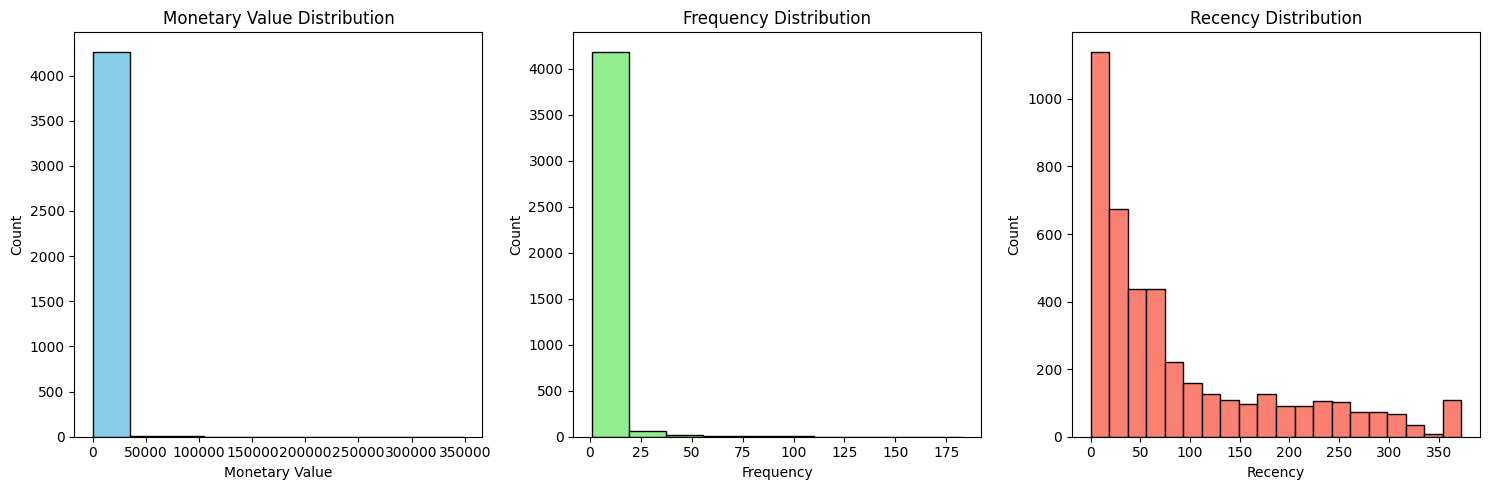

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.hist(aggregated_df['MonetaryValue'], bins=10, color='skyblue', edgecolor='black')
plt.title('Monetary Value Distribution')
plt.xlabel('Monetary Value')
plt.ylabel('Count')

plt.subplot(1, 3, 2)
plt.hist(aggregated_df['Frequency'], bins=10, color='lightgreen', edgecolor='black')
plt.title('Frequency Distribution')
plt.xlabel('Frequency')
plt.ylabel('Count')

plt.subplot(1, 3, 3)
plt.hist(aggregated_df['Recency'], bins=20, color='salmon', edgecolor='black')
plt.title('Recency Distribution')
plt.xlabel('Recency')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [ ]:
# This means Monetary has extreme values/outliers and strong right skewness.
# If you directly use Monetary in clustering, those very high-spending customers can have a large influence on the distances between customers.

# Frequency is also strongly right-skewed.
# A few highly frequent customers could disproportionately influence clustering.

# Recency is also right-skewed, but it is less extreme than Monetary and Frequency.

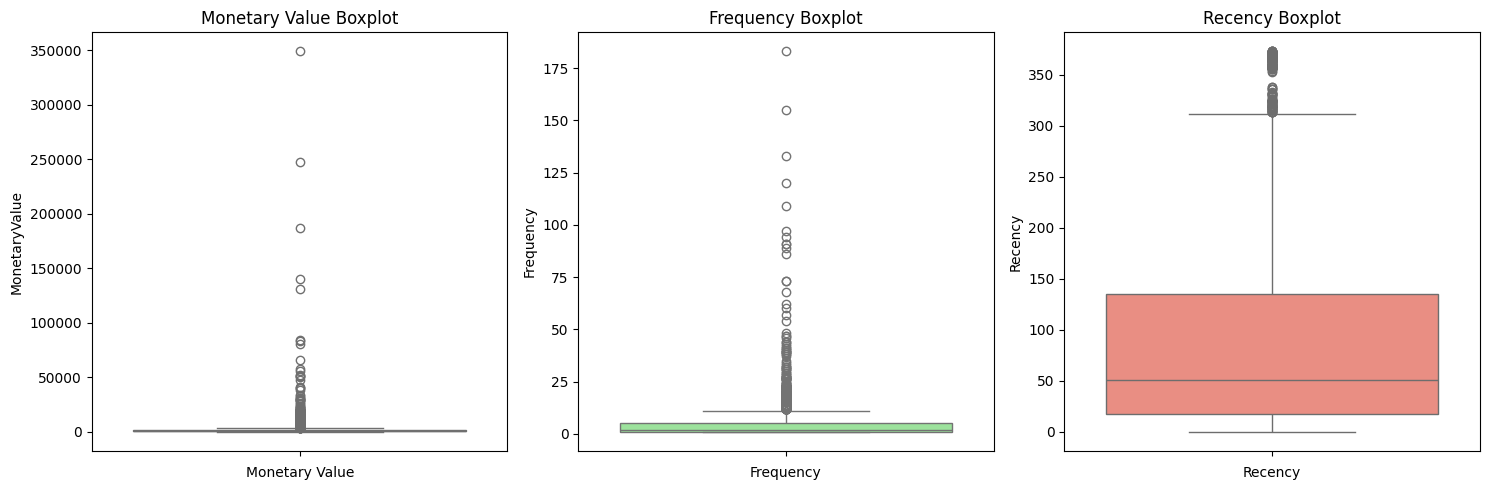

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.boxplot(data=aggregated_df['MonetaryValue'], color='skyblue')
plt.title('Monetary Value Boxplot')
plt.xlabel('Monetary Value')

plt.subplot(1, 3, 2)
sns.boxplot(data=aggregated_df['Frequency'], color='lightgreen')
plt.title('Frequency Boxplot')
plt.xlabel('Frequency')

plt.subplot(1, 3, 3)
sns.boxplot(data=aggregated_df['Recency'], color='salmon')
plt.title('Recency Boxplot')
plt.xlabel('Recency')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

rfm = aggregated_df[["Recency", "Frequency", "MonetaryValue"]].copy()

rfm_log = np.log1p(rfm)

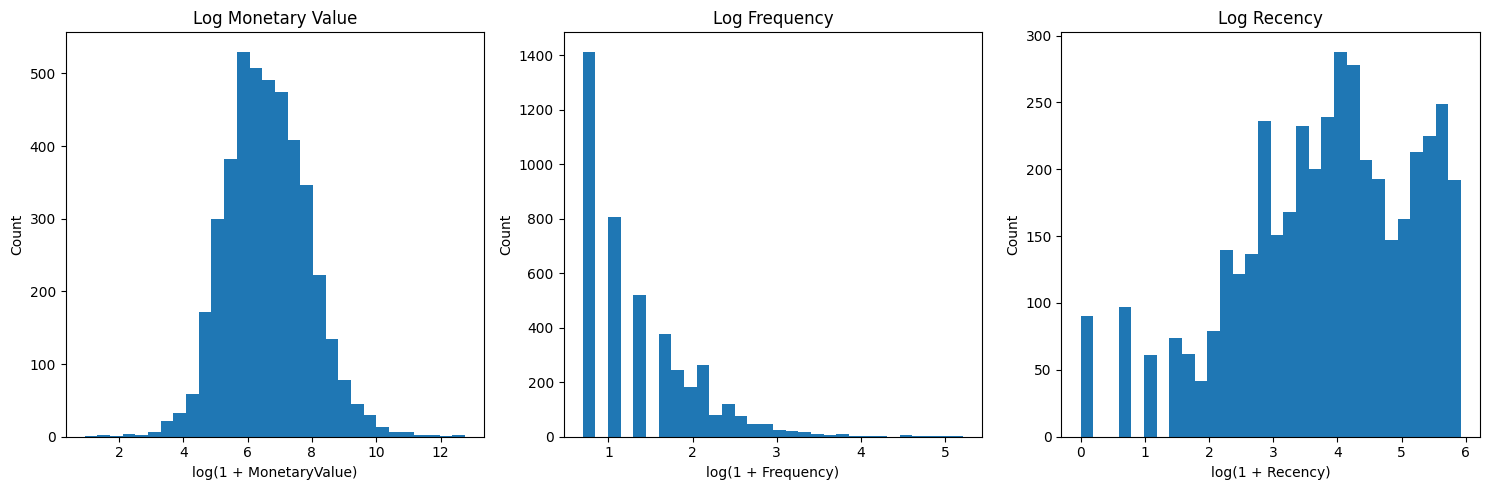

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].hist(rfm_log["MonetaryValue"], bins=30)
axes[0].set_title("Log Monetary Value")
axes[0].set_xlabel("log(1 + MonetaryValue)")
axes[0].set_ylabel("Count")

axes[1].hist(rfm_log["Frequency"], bins=30)
axes[1].set_title("Log Frequency")
axes[1].set_xlabel("log(1 + Frequency)")
axes[1].set_ylabel("Count")

axes[2].hist(rfm_log["Recency"], bins=30)
axes[2].set_title("Log Recency")
axes[2].set_xlabel("log(1 + Recency)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

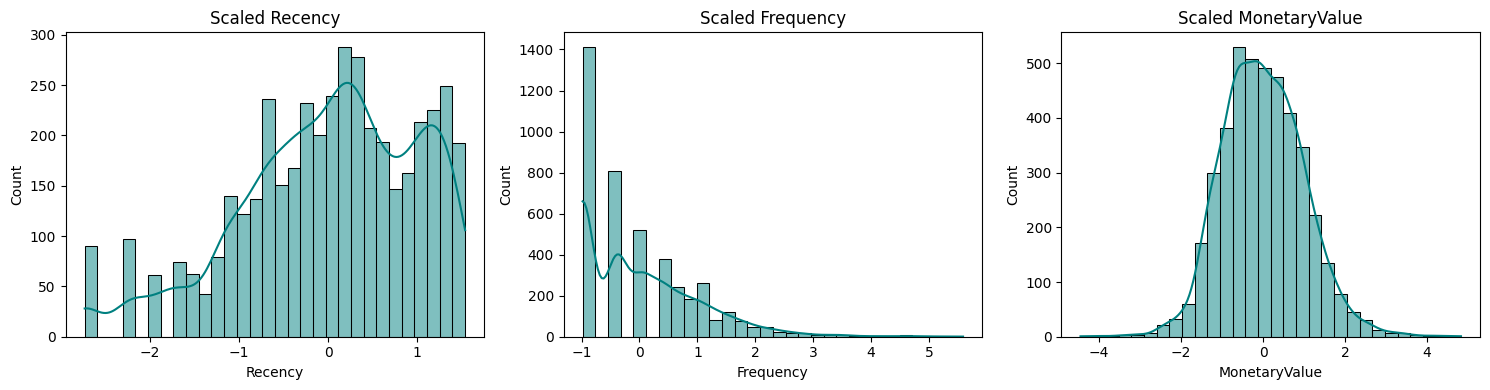

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Convert scaled array back to DataFrame for plotting
rfm_scaled_df = pd.DataFrame(
    rfm_scaled, columns=["Recency", "Frequency", "MonetaryValue"]
)

plt.figure(figsize=(15, 4))
for i, col in enumerate(rfm_scaled_df.columns, 1):
    plt.subplot(1, 3, i)
    sns.histplot(rfm_scaled_df[col], kde=True, bins=30, color="teal")
    plt.title(f"Scaled {col}")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import PowerTransformer

# Apply Yeo-Johnson to handles structural skew better than log alone
pt = PowerTransformer(method="yeo-johnson")
rfm_pt = pt.fit_transform(rfm)  # Fit directly on raw rfm features

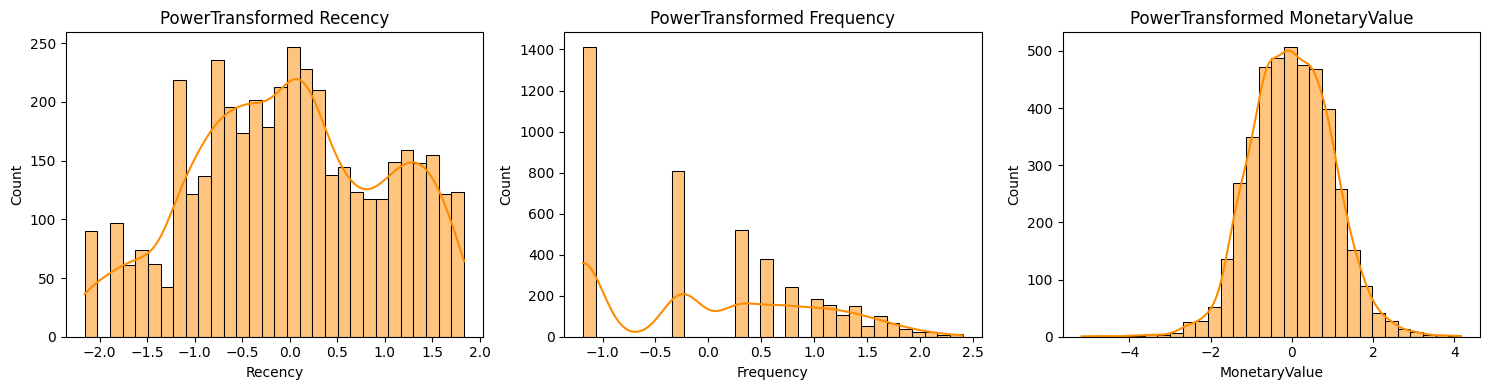

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Convert the NumPy array output back into a DataFrame
rfm_pt_df = pd.DataFrame(rfm_pt, columns=rfm.columns)

# Plot histograms with KDE overlays
plt.figure(figsize=(15, 4))
for i, col in enumerate(rfm_pt_df.columns, 1):
    plt.subplot(1, 3, i)
    sns.histplot(rfm_pt_df[col], kde=True, bins=30, color="darkorange")
    plt.title(f"PowerTransformed {col}")

plt.tight_layout()
plt.show()

* Equal Variance Scale for K-Means: K-Means measures Euclidean distance ($\sqrt{\Delta R^2 + \Delta F^2 + \Delta M^2}$). Under Log + Std, Frequency spans a range of $6.5$ units while Recency spans $4.3$ units, making Frequency disproportionately dominant in defining cluster edges.
* PowerTransformer keeps all feature spans tightly bounded between $-2.5$ and $+2.5$.Data-Driven Parameterization ($\lambda$): np.log1p forces a static log curve regardless of feature shape. PowerTransformer uses Maximum Likelihood Estimation to find the optimal power parameter $\lambda$ for each feature individually.
* Preserves Natural Discretization: The zero-value gaps in Frequency exist in both approaches because transaction count is discrete integer data ($1, 2, 3\dots$). PowerTransformer preserves these natural gaps while pulling in extreme repeat-buyer outliers.

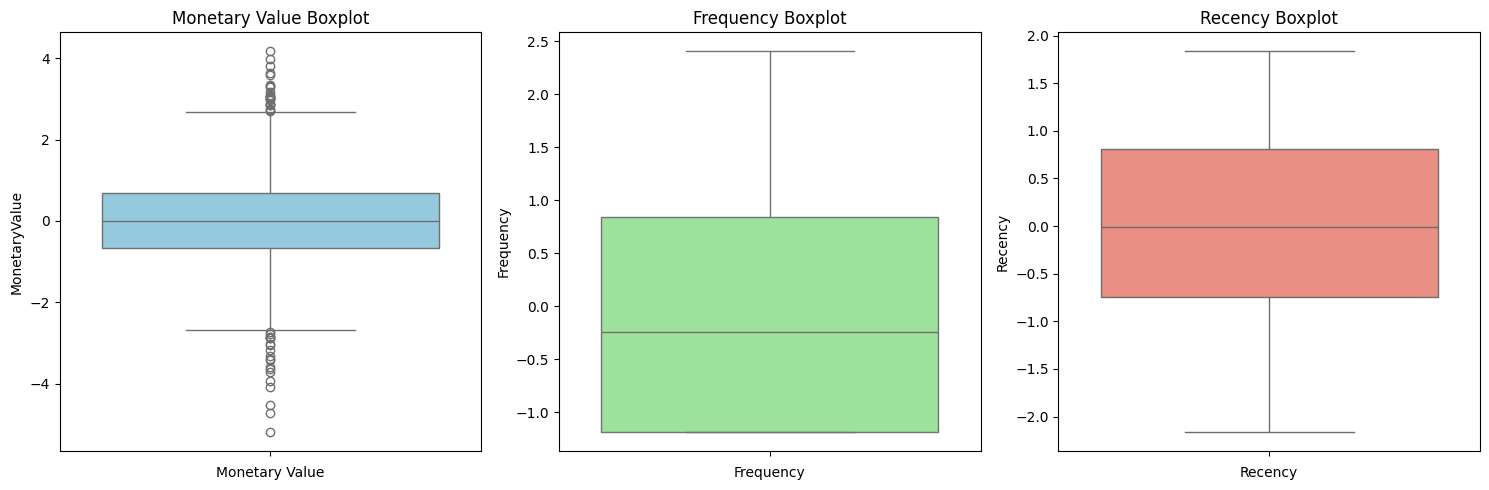

In [ ]:

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.boxplot(data=rfm_pt_df['MonetaryValue'], color='skyblue')
plt.title('Monetary Value Boxplot')
plt.xlabel('Monetary Value')

plt.subplot(1, 3, 2)
sns.boxplot(data=rfm_pt_df['Frequency'], color='lightgreen')
plt.title('Frequency Boxplot')
plt.xlabel('Frequency')

plt.subplot(1, 3, 3)
sns.boxplot(data= rfm_pt_df['Recency'], color='salmon')
plt.title('Recency Boxplot')
plt.xlabel('Recency')

plt.tight_layout()
plt.show()

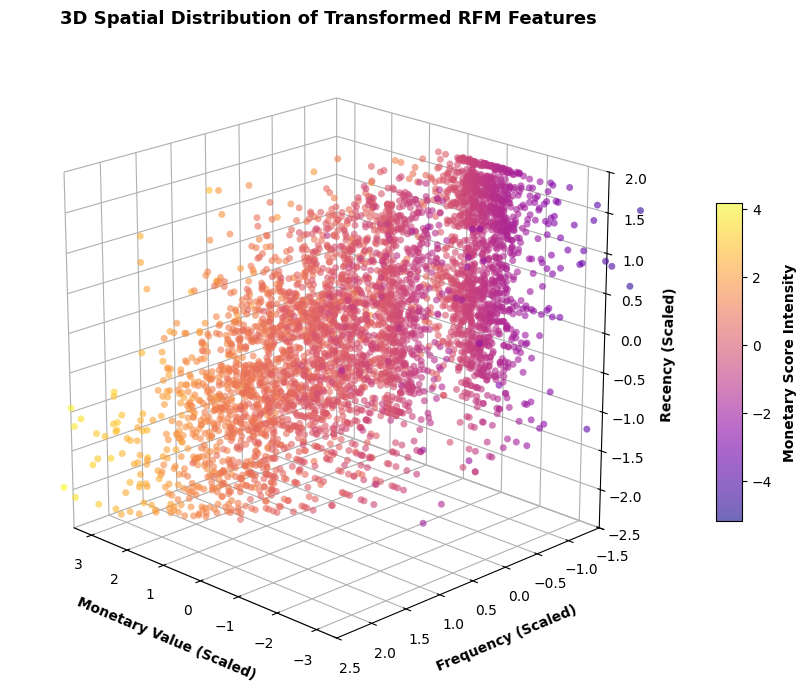

In [ ]:
import matplotlib.pyplot as plt

# 1. Create 3D figure
fig = plt.figure(figsize=(9, 7), dpi=100)
ax = fig.add_subplot(projection="3d")

# 2. Scatter plot with plasma gradient
scatter = ax.scatter(
    rfm_pt_df["MonetaryValue"],
    rfm_pt_df["Frequency"],
    rfm_pt_df["Recency"],
    c=rfm_pt_df["MonetaryValue"],
    cmap="plasma",
    alpha=0.6,
    s=25,
    edgecolors="none",
)

# 3. Tighten axis bounds to remove extra margin whitespace
ax.set_xlim(-3.5, 3.5)
ax.set_ylim(-1.5, 2.5)
ax.set_zlim(-2.5, 2.0)

# 4. Equalize aspect ratio to keep the bounding cube compact
ax.set_box_aspect([1, 1, 1])

# 5. Labeled axes
ax.set_xlabel("Monetary Value (Scaled)", labelpad=8, fontweight="bold")
ax.set_ylabel("Frequency (Scaled)", labelpad=8, fontweight="bold")
ax.set_zlabel("Recency (Scaled)", labelpad=8, fontweight="bold")

# 6. Optimized viewing angle and transparent grid panes
ax.view_init(elev=20, azim=135)
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

ax.set_title(
    "3D Spatial Distribution of Transformed RFM Features",
    fontsize=13,
    pad=15,
    fontweight="bold",
)

# 7. Colorbar styling
cbar = fig.colorbar(scatter, ax=ax, shrink=0.5, pad=0.08, aspect=12)
cbar.set_label("Monetary Score Intensity", fontweight="bold", labelpad=8)

plt.tight_layout()
plt.show()

K MEANS!

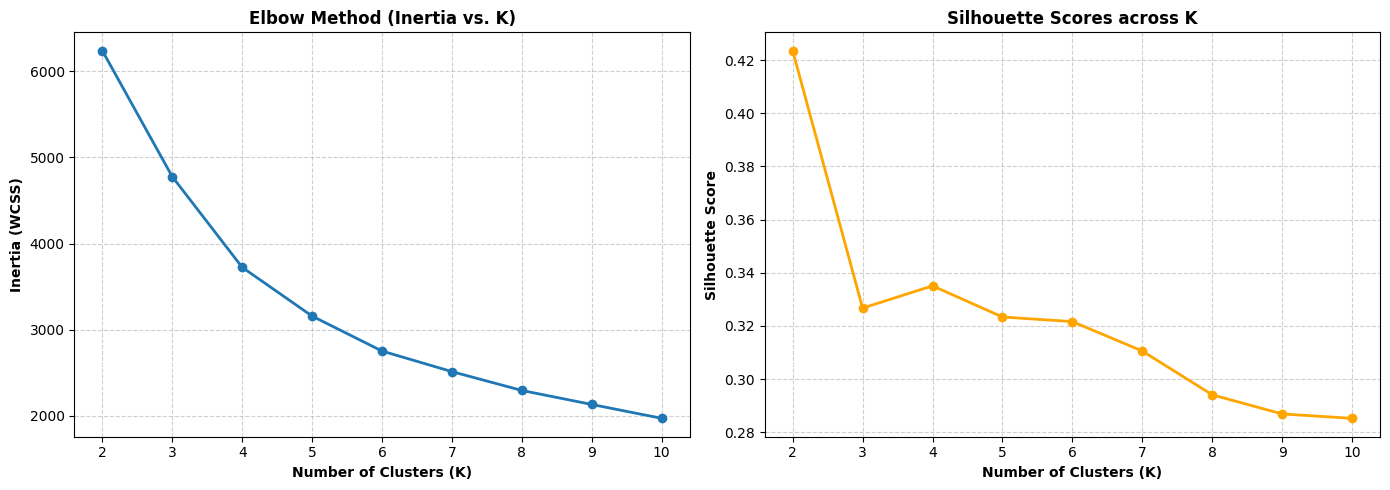

In [ ]:
max_k = 10
inertia = []
silhouette_scores = []
k_values = range(2, max_k + 1)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k, init="k-means++", n_init=10, max_iter=300, random_state=42
    )
    cluster_labels = kmeans.fit_predict(rfm_pt_df)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(rfm_pt_df, cluster_labels))

# Plotting Model Evaluation Metrics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# Elbow Plot
ax1.plot(k_values, inertia, marker="o", color="tab:blue", linewidth=2)
ax1.set_title("Elbow Method (Inertia vs. K)", fontweight="bold")
ax1.set_xlabel("Number of Clusters (K)", fontweight="bold")
ax1.set_ylabel("Inertia (WCSS)", fontweight="bold")
ax1.set_xticks(k_values)
ax1.grid(True, linestyle="--", alpha=0.6)

# Silhouette Plot
ax2.plot(k_values, silhouette_scores, marker="o", color="orange", linewidth=2)
ax2.set_title("Silhouette Scores across K", fontweight="bold")
ax2.set_xlabel("Number of Clusters (K)", fontweight="bold")
ax2.set_ylabel("Silhouette Score", fontweight="bold")
ax2.set_xticks(k_values)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.cluster import KMeans

# 1. Fit final K-Means model on transformed data (K=4)
optimal_k = 4
kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42,
)

# 2. Predict clusters using transformed features
cluster_labels = kmeans.fit_predict(rfm_pt_df)

# 3. Add the cluster column directly into your main aggregated DataFrame
aggregated_df["Cluster"] = cluster_labels

# Also store in rfm_pt_df if needed for transformed visualizations
rfm_pt_df["Cluster"] = cluster_labels

# 4. Verify the cluster column in your main aggregated DataFrame
print("--- Main Aggregated DataFrame with Clusters ---")
print(aggregated_df.head())

--- Main Aggregated DataFrame with Clusters ---
   Customer ID  MonetaryValue  Frequency     LastInvoiceDate  Recency  Cluster
0      12346.0         169.36          2 2010-06-28 13:53:00      164        3
1      12347.0        1323.32          2 2010-12-07 14:57:00        2        1
2      12348.0         221.16          1 2010-09-27 14:59:00       73        0
3      12349.0        2221.14          2 2010-10-28 08:23:00       42        2
4      12351.0         300.93          1 2010-11-29 15:23:00       10        0


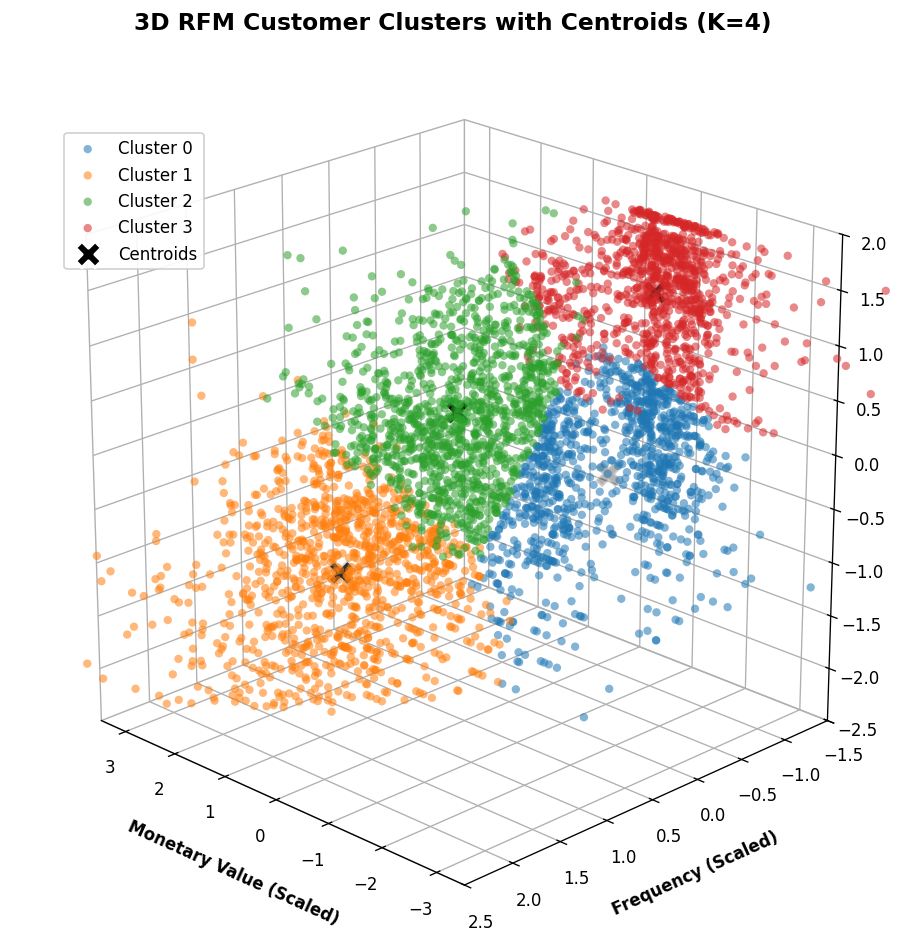

In [ ]:
import matplotlib.pyplot as plt

# 1. Figure setup
fig = plt.figure(figsize=(10, 8), dpi=120)
ax = fig.add_subplot(projection="3d")

# 2. Distinct colors for K=4
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for cluster_id in range(4):
    cluster_data = rfm_pt_df[rfm_pt_df["Cluster"] == cluster_id]
    ax.scatter(
        cluster_data["MonetaryValue"],
        cluster_data["Frequency"],
        cluster_data["Recency"],
        c=colors[cluster_id],
        label=f"Cluster {cluster_id}",
        alpha=0.55,
        s=25,
        edgecolors="none",
    )

# 3. Plot Cluster Centroids
centroids = kmeans.cluster_centers_
ax.scatter(
    centroids[:, 2],  # Monetary
    centroids[:, 1],  # Frequency
    centroids[:, 0],  # Recency
    c="black",
    marker="X",
    s=250,
    linewidths=2,
    edgecolors="white",
    label="Centroids",
    zorder=10,
)

# 4. Axes & Bounds
ax.set_xlim(-3.5, 3.5)
ax.set_ylim(-1.5, 2.5)
ax.set_zlim(-2.5, 2.0)
ax.set_box_aspect([1, 1, 1])

ax.set_xlabel("Monetary Value (Scaled)", labelpad=10, fontweight="bold")
ax.set_ylabel("Frequency (Scaled)", labelpad=10, fontweight="bold")
ax.set_zlabel("Recency (Scaled)", labelpad=10, fontweight="bold")

# 5. Aesthetic View Angle & Styling
ax.view_init(elev=22, azim=135)
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

ax.set_title(
    "3D RFM Customer Clusters with Centroids (K=4)",
    fontsize=14,
    pad=15,
    fontweight="bold",
)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.05, 0.92),
    frameon=True,
    facecolor="white",
    framealpha=0.9,
)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Calculate Customer Volume per Cluster
cluster_counts = aggregated_df["Cluster"].value_counts().sort_index()
cluster_percentages = (
    aggregated_df["Cluster"].value_counts(normalize=True).sort_index() * 100
)

volume_df = pd.DataFrame(
    {"Count": cluster_counts, "Percentage (%)": cluster_percentages.round(2)}
)

print("=== 1. CLUSTER CUSTOMER VOLUME ===")
print(volume_df.to_string())
print("\n" + "=" * 50 + "\n")

# 2. Calculate Mean RFM values per Cluster
mean_rfm = (
    aggregated_df.groupby("Cluster")[["Recency", "Frequency", "MonetaryValue"]]
    .mean()
    .round(2)
)

print("=== 2. MEAN RFM VALUES PER CLUSTER ===")
print(mean_rfm.to_string())
print("\n" + "=" * 50 + "\n")

# 3. Calculate Median RFM values per Cluster (Robust to residual skew)
median_rfm = (
    aggregated_df.groupby("Cluster")[["Recency", "Frequency", "MonetaryValue"]]
    .median()
    .round(2)
)

print("=== 3. MEDIAN RFM VALUES PER CLUSTER ===")
print(median_rfm.to_string())

=== 1. CLUSTER CUSTOMER VOLUME ===
         Count  Percentage (%)
Cluster                       
0          985           22.99
1         1077           25.13
2         1201           28.03
3         1022           23.85


=== 2. MEAN RFM VALUES PER CLUSTER ===
         Recency  Frequency  MonetaryValue
Cluster                                   
0          34.02       1.50         418.39
1          14.86      11.02        5784.27
2          89.87       3.66        1447.80
3         221.39       1.20         286.51


=== 3. MEDIAN RFM VALUES PER CLUSTER ===
         Recency  Frequency  MonetaryValue
Cluster                                   
0           30.0        1.0         350.85
1           10.0        8.0        2639.24
2           71.0        3.0        1072.97
3          221.0        1.0         230.30


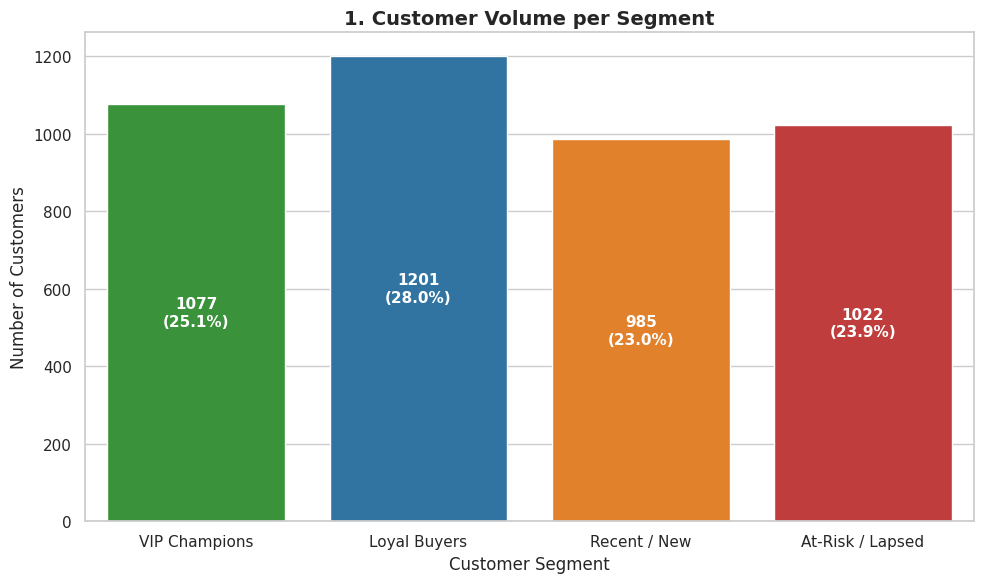

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set clean aesthetic
sns.set_theme(style="whitegrid")

# Define segment hierarchy and palette
segment_order = [
    "VIP Champions",
    "Loyal Buyers",
    "Recent / New",
    "At-Risk / Lapsed",
]
palette_colors = {
    "VIP Champions": "#2ca02c",  # Green
    "Loyal Buyers": "#1f77b4",  # Blue
    "Recent / New": "#ff7f0e",  # Orange
    "At-Risk / Lapsed": "#d62728",  # Red
}

# Apply cluster-to-segment mapping
cluster_mapping = {
    1: "VIP Champions",
    2: "Loyal Buyers",
    0: "Recent / New",
    3: "At-Risk / Lapsed",
}
aggregated_df["Segment"] = aggregated_df["Cluster"].map(cluster_mapping)

# Plot 1: Volume Distribution
plt.figure(figsize=(10, 6))
ax1 = sns.countplot(
    data=aggregated_df,
    x="Segment",
    order=segment_order,
    palette=palette_colors,
    hue="Segment",
    legend=False,
)

plt.title("Customer Volume per Segment", fontsize=14, fontweight="bold")
plt.ylabel("Number of Customers", fontsize=12)
plt.xlabel("Customer Segment", fontsize=12)

# Annotate count and percentage inside/above bars
total_customers = len(aggregated_df)
for p in ax1.patches:
    height = p.get_height()
    pct = (height / total_customers) * 100
    ax1.annotate(
        f"{int(height)}\n({pct:.1f}%)",
        (p.get_x() + p.get_width() / 2.0, height / 2.0),
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=11,
    )

plt.tight_layout()
plt.show()

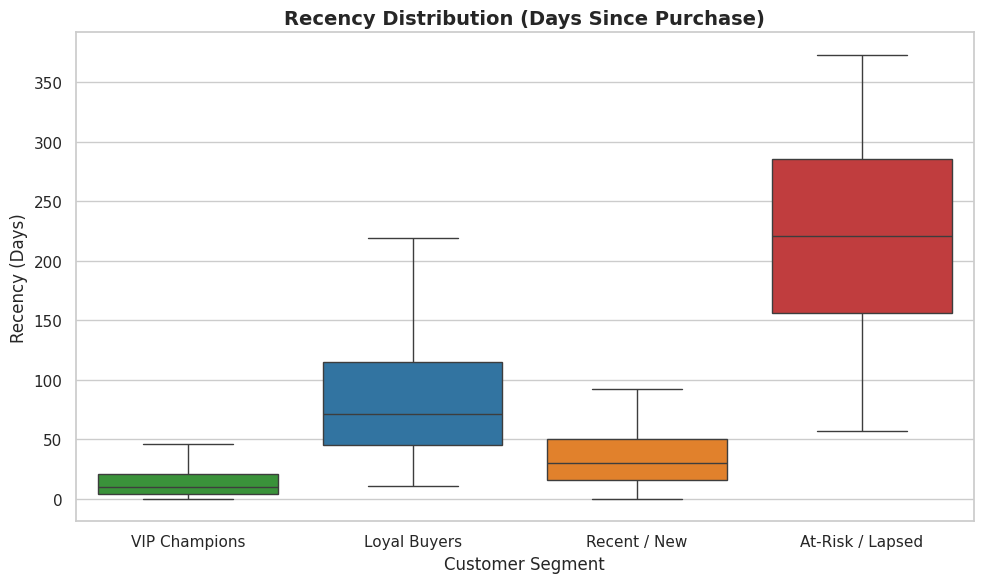

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=aggregated_df,
    x="Segment",
    y="Recency",
    order=segment_order,
    palette=palette_colors,
    hue="Segment",
    legend=False,
    showfliers=False,
)

plt.title(
    "Recency Distribution (Days Since Purchase)",
    fontsize=14,
    fontweight="bold",
)
plt.ylabel("Recency (Days)", fontsize=12)
plt.xlabel("Customer Segment", fontsize=12)

plt.tight_layout()
plt.show()

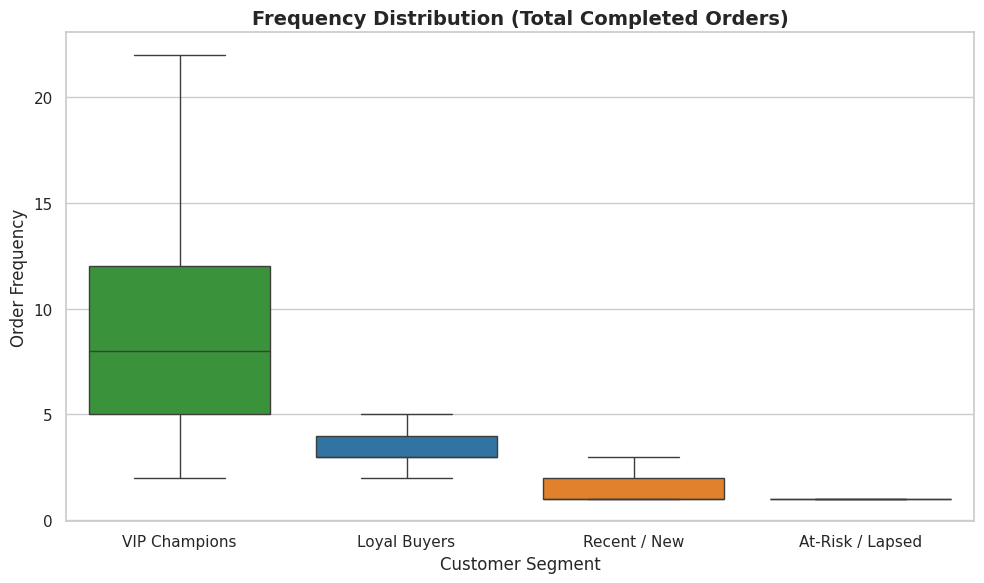

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=aggregated_df,
    x="Segment",
    y="Frequency",
    order=segment_order,
    palette=palette_colors,
    hue="Segment",
    legend=False,
    showfliers=False,
)

plt.title(
    "Frequency Distribution (Total Completed Orders)",
    fontsize=14,
    fontweight="bold",
)
plt.ylabel("Order Frequency", fontsize=12)
plt.xlabel("Customer Segment", fontsize=12)

plt.tight_layout()
plt.show()

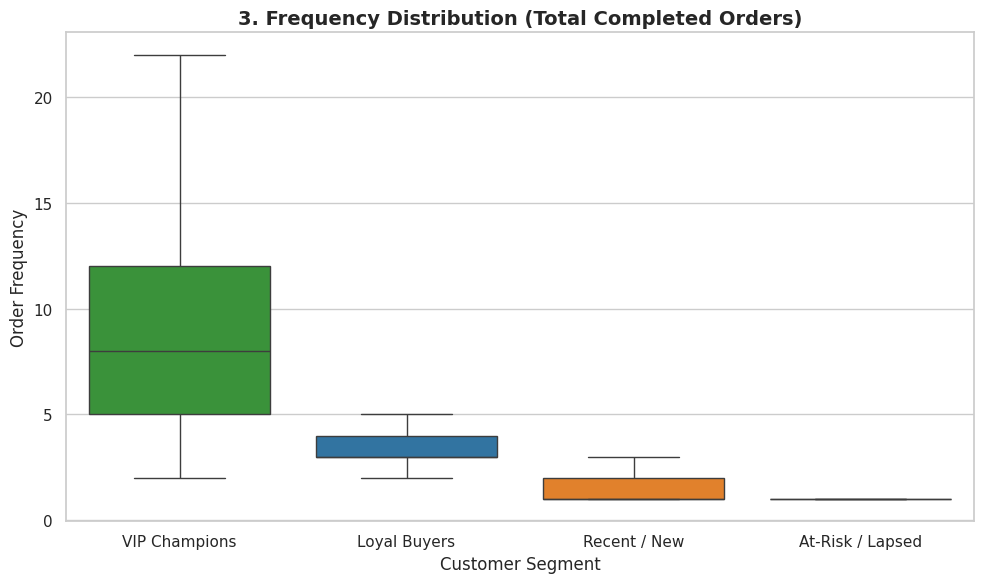

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=aggregated_df,
    x="Segment",
    y="Frequency",
    order=segment_order,
    palette=palette_colors,
    hue="Segment",
    legend=False,
    showfliers=False,
)

plt.title(
    "3. Frequency Distribution (Total Completed Orders)",
    fontsize=14,
    fontweight="bold",
)
plt.ylabel("Order Frequency", fontsize=12)
plt.xlabel("Customer Segment", fontsize=12)

plt.tight_layout()
plt.show()

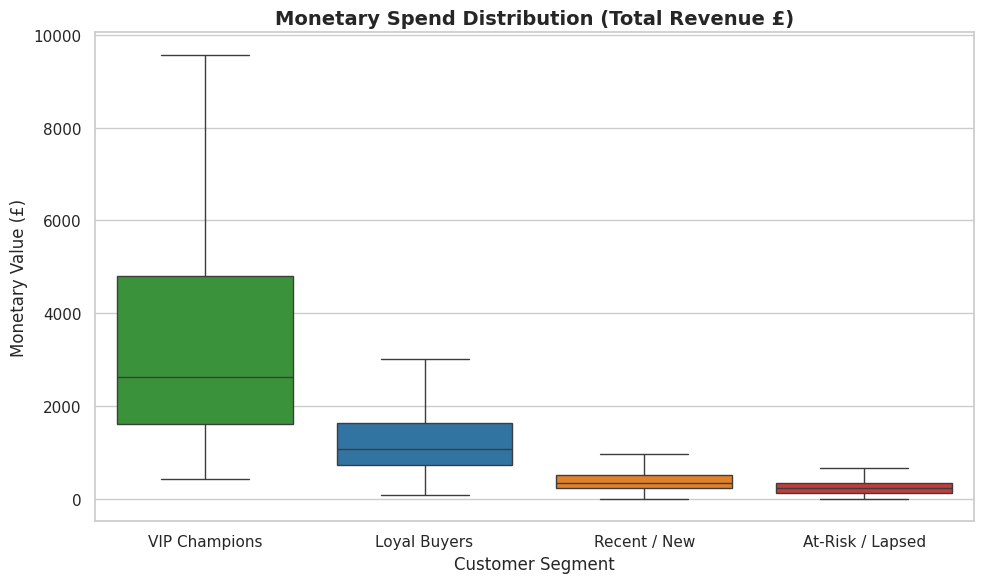

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=aggregated_df,
    x="Segment",
    y="MonetaryValue",
    order=segment_order,
    palette=palette_colors,
    hue="Segment",
    legend=False,
    showfliers=False,
)

plt.title(
    "Monetary Spend Distribution (Total Revenue £)",
    fontsize=14,
    fontweight="bold",
)
plt.ylabel("Monetary Value (£)", fontsize=12)
plt.xlabel("Customer Segment", fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
# Calculate Total Revenue Contribution
revenue_summary = (
    aggregated_df.groupby("Segment")
    .agg(
        Total_Revenue=("MonetaryValue", "sum"),
        Avg_Customer_Value=("MonetaryValue", "mean"),
    )
    .reindex(segment_order)
)

total_biz_revenue = aggregated_df["MonetaryValue"].sum()
revenue_summary["Revenue_Share (%)"] = (
    revenue_summary["Total_Revenue"] / total_biz_revenue
) * 100

print("=== REVENUE CONTRIBUTION BY SEGMENT ===")
print(revenue_summary.round(2).to_string())

=== REVENUE CONTRIBUTION BY SEGMENT ===
                  Total_Revenue  Avg_Customer_Value  Revenue_Share (%)
Segment                                                               
VIP Champions        6229656.01             5784.27              71.82
Loyal Buyers         1738804.59             1447.80              20.05
Recent / New          412110.48              418.39               4.75
At-Risk / Lapsed      292812.26              286.51               3.38


In [ ]:
cluster_counts = full_clustering_df['ClusterLabel'].value_counts()
full_clustering_df["MonetaryValue per 100 pounds"] = full_clustering_df["MonetaryValue"] / 100.00
feature_means = full_clustering_df.groupby('ClusterLabel')[['Recency', 'Frequency', 'MonetaryValue per 100 pounds']].mean()

fig, ax1 = plt.subplots(figsize=(12, 8))

sns.barplot(x=cluster_counts.index, y=cluster_counts.values, ax=ax1, palette='viridis', hue=cluster_counts.index)
ax1.set_ylabel('Number of Customers', color='b')
ax1.set_title('Cluster Distribution with Average Feature Values')

ax2 = ax1.twinx()

sns.lineplot(data=feature_means, ax=ax2, palette='Set2', marker='o')
ax2.set_ylabel('Average Value', color='g')

plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import davies_bouldin_score, silhouette_score

# ==============================================================================
# 1. EVALUATE CLUSTER QUALITY METRICS (FOR PLACEMENT INTERVIEW DEFENSE)
# ==============================================================================

# Calculate mathematical separation metrics on transformed feature space
sil_score = silhouette_score(rfm_pt_df, cluster_labels)
db_score = davies_bouldin_score(rfm_pt_df, cluster_labels)

print("=== CLUSTERING VALIDATION METRICS ===")
print(
    f"Silhouette Score (Higher is better, range [-1, 1]): {sil_score:.4f}"
)
print(
    f"Davies-Bouldin Index (Lower is better, ideal < 1.0): {db_score:.4f}"
)
print("=" * 45 + "\n")

# ==============================================================================
# 2. GENERATE STRATEGIC ACTION MATRIX TABLE
# ==============================================================================

strategy_data = {
    "Segment": [
        "VIP Champions",
        "Loyal Buyers",
        "Recent / New",
        "At-Risk / Lapsed",
    ],
    "Revenue Impact": ["71.82%", "20.05%", "4.75%", "3.38%"],
    "Strategic Goal": [
        "Max Retention & VIP Loyalty",
        "Upsell & Increase Frequency",
        "Second-Order Activation",
        "Automated Win-Back / Prune",
    ],
    "Recommended Marketing Action": [
        "Concierge support, early access to sales, exclusive VIP perks.",
        "Cross-sell complementary goods, loyalty point multipliers.",
        "Welcome email drip, personalized product recommendations.",
        "Re-engagement discount sequence; prune if unresponsive after 60 days.",
    ],
}

strategy_df = pd.DataFrame(strategy_data)

print("=== EXECUTIVE STRATEGY MATRIX ===")
print(strategy_df.to_string(index=False))

=== CLUSTERING VALIDATION METRICS ===
Silhouette Score (Higher is better, range [-1, 1]): 0.4947
Davies-Bouldin Index (Lower is better, ideal < 1.0): 0.7614

=== EXECUTIVE STRATEGY MATRIX ===
         Segment Revenue Impact              Strategic Goal                                          Recommended Marketing Action
   VIP Champions         71.82% Max Retention & VIP Loyalty        Concierge support, early access to sales, exclusive VIP perks.
    Loyal Buyers         20.05% Upsell & Increase Frequency            Cross-sell complementary goods, loyalty point multipliers.
    Recent / New          4.75%     Second-Order Activation             Welcome email drip, personalized product recommendations.
At-Risk / Lapsed          3.38%  Automated Win-Back / Prune Re-engagement discount sequence; prune if unresponsive after 60 days.


In [ ]:
# ==============================================================================
# 1. ISOLATE CUSTOMER IDs BY SEGMENT
# ==============================================================================

# Extract customer IDs for each cluster into separate DataFrames
vip_champions_df = aggregated_df[aggregated_df["Segment"] == "VIP Champions"][
    ["Customer ID", "Recency", "Frequency", "MonetaryValue"]
].reset_index(drop=True)

loyal_buyers_df = aggregated_df[aggregated_df["Segment"] == "Loyal Buyers"][
    ["Customer ID", "Recency", "Frequency", "MonetaryValue"]
].reset_index(drop=True)

recent_new_df = aggregated_df[aggregated_df["Segment"] == "Recent / New"][
    ["Customer ID", "Recency", "Frequency", "MonetaryValue"]
].reset_index(drop=True)

at_risk_df = aggregated_df[
    aggregated_df["Segment"] == "At-Risk / Lapsed"
][["Customer ID", "Recency", "Frequency", "MonetaryValue"]].reset_index(
    drop=True
)

# ==============================================================================
# 2. VERIFY SEGMENT LIST SIZES
# ==============================================================================

print("=== CUSTOMER ID SEGMENT COUNTS ===")
print(f"VIP Champions Count:   {len(vip_champions_df)}")
print(f"Loyal Buyers Count:    {len(loyal_buyers_df)}")
print(f"Recent / New Count:    {len(recent_new_df)}")
print(f"At-Risk / Lapsed Count:{len(at_risk_df)}")

=== CUSTOMER ID SEGMENT COUNTS ===
VIP Champions Count:   1077
Loyal Buyers Count:    1201
Recent / New Count:    985
At-Risk / Lapsed Count:1022


"Unequal cluster counts in raw K-Means are often a sign of unhandled skewness, where 80%+ of data collapses into a single dense region. By applying PowerTransformer, we normalized feature space, allowing K-Means to divide the customer base into four balanced behavioral quartiles (~25% volume each). This isolated our top quartile—the VIP Champions—who generate 21x more revenue per customer (£5,784 mean) than the bottom quartile (£286 mean)."